# TSA Complaint Trends: A Traveler's Guide to Airport Security
### DSC640-T302 Data Presentation & Visualization | Week 9-10
### Kyle Gotzman
---

## Story Framework

**Audience:** Everyday air travelers and frequent flyers who want practical insight
into where and when TSA complaints happen — no aviation expertise required.

**Purpose:** Equip travelers with data-backed recommendations about which airports
and scenarios tend to generate the most complaints, so they can plan ahead,
set realistic expectations, and know their rights. *This is a call to action, not
just an FYI.*

**Medium:** Infographic-style Python notebook — bold visuals, narrative-driven titles,
minimal jargon, exportable to PDF.

**Required Visuals (3 of 6):** Spatial / Choropleth Map, Heat Map, Box Plot

**Datasets:**
1. `complaints-by-airport.csv` — complaint counts by airport and month
2. `complaints-by-category.csv` — complaint counts broken out by category
3. `complaints-by-subcategory.csv` — further granularity by subcategory
4. `iata-icao.csv` — airport names, codes, and coordinates

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns
import geopandas as gpd
import warnings

warnings.filterwarnings('ignore')

from pathlib import Path

# Infographic palette
TSA_BLUE  = '#003366'
ALERT_RED = '#D32F2F'
AMBER     = '#FF8F00'
SKY_BLUE  = '#4FC3F7'
SAGE      = '#66BB6A'
VIOLET    = '#AB47BC'
CORAL     = '#FF7043'
TEAL      = '#26A69A'
PALETTE   = [TSA_BLUE, ALERT_RED, AMBER, SKY_BLUE, SAGE, VIOLET, CORAL, TEAL]

sns.set_theme(style='white', palette=PALETTE)
plt.rcParams.update({
    'figure.figsize':    (12, 6),
    'figure.dpi':        120,
    'savefig.dpi':       150,
    'font.size':         11,
    'axes.titlesize':    16,
    'axes.titleweight':  'bold',
    'axes.labelsize':    12,
    'figure.facecolor':  'white',
    'axes.facecolor':    'white',
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

---
## 1 | Load the Data
Four public datasets power this analysis — three from TSA complaint FOIA releases
(hosted on GitHub) and one open IATA/ICAO airport reference table.

In [2]:
DATA_DIR = Path('.')
if not (DATA_DIR / 'complaints-by-airport.csv').exists():
    DATA_DIR = Path('WK9-10')

airport_raw  = pd.read_csv(DATA_DIR / 'complaints-by-airport.csv')
category_raw = pd.read_csv(DATA_DIR / 'complaints-by-category.csv')
subcat_raw   = pd.read_csv(DATA_DIR / 'complaints-by-subcategory.csv')
iata_raw     = pd.read_csv(DATA_DIR / 'iata-icao.csv')

for name, df in [('Complaints by Airport', airport_raw),
                 ('Complaints by Category', category_raw),
                 ('Complaints by Subcategory', subcat_raw),
                 ('IATA/ICAO Reference', iata_raw)]:
    print(f"{name:30s}  {df.shape[0]:>7,} rows x {df.shape[1]} cols")

Complaints by Airport            41,721 rows x 4 cols
Complaints by Category          241,588 rows x 7 cols
Complaints by Subcategory       504,512 rows x 11 cols
IATA/ICAO Reference               8,937 rows x 7 cols


In [3]:
for name, df in [('Airport', airport_raw), ('Category', category_raw),
                 ('Subcategory', subcat_raw), ('IATA/ICAO', iata_raw)]:
    print(f"\n{'='*65}\n  {name}\n{'='*65}")
    display(df.head(3))
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    if len(nulls):
        print(f"  Nulls: {dict(nulls)}")
    else:
        print("  Nulls: none")


  Airport


,pdf_report_date,airport,year_month,count
0,2019-02,ABE,2015-01,0
1,2019-02,ABE,2015-02,0
2,2019-02,ABE,2015-03,0


  Nulls: {'airport': np.int64(109)}

  Category


,pdf_report_date,airport,category,year_month,count,clean_cat,clean_cat_status
0,2019-02,ABE,Hazardous Materials Safety,2015-01,0,Hazardous Materials Safety,original
1,2019-02,ABE,Mishandling of Passenger Property,2015-01,0,Mishandling of Passenger Property,original
2,2019-02,ABE,Hazardous Materials Safety,2015-02,0,Hazardous Materials Safety,original


  Nulls: {'airport': np.int64(4042)}

  Subcategory


,pdf_report_date,airport,category,subcategory,year_month,count,clean_cat,clean_subcat,clean_cat_status,clean_subcat_status,is_category_prefix_removed
0,2019-02,ABE,Hazardous Materials Safety,General,2015-01,0,Hazardous Materials Safety,General,original,original,False
1,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-01,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False
2,2019-02,ABE,Hazardous Materials Safety,General,2015-02,0,Hazardous Materials Safety,General,original,original,False


  Nulls: {'airport': np.int64(13464)}

  IATA/ICAO


,country_code,region_name,iata,icao,airport,latitude,longitude
0,AE,Abu Zaby,AAN,OMAL,Al Ain International Airport,24.2617,55.6092
1,AE,Abu Zaby,AUH,OMAA,Abu Dhabi International Airport,24.4330,54.6511
2,AE,Abu Zaby,AYM,NaN,Yas Island Seaplane Base,24.4670,54.6103


  Nulls: {'country_code': np.int64(32), 'icao': np.int64(1143)}


---
## 2 | Clean & Prepare the Data

**Key steps:**
- **Deduplicate** — multiple PDF report dates can cover the same month; we keep only
  the most recent report for each airport / time-period combination.
- **Parse dates** for time-series analysis.
- **Filter IATA to U.S. airports** and merge for geographic coordinates and full names.
- **Document all transformations** for ethical transparency.

In [4]:
# Deduplicate: retain only the latest report per observation
airport_df = (airport_raw
    .sort_values('pdf_report_date')
    .drop_duplicates(subset=['airport', 'year_month'], keep='last')
    .copy())

category_df = (category_raw
    .sort_values('pdf_report_date')
    .drop_duplicates(subset=['airport', 'clean_cat', 'year_month'], keep='last')
    .copy())

subcat_df = (subcat_raw
    .sort_values('pdf_report_date')
    .drop_duplicates(subset=['airport', 'clean_cat', 'clean_subcat', 'year_month'], keep='last')
    .copy())

# Parse dates
airport_df['date']  = pd.to_datetime(airport_df['year_month']  + '-01')
category_df['date'] = pd.to_datetime(category_df['year_month'] + '-01')
airport_df['year']  = airport_df['date'].dt.year
airport_df['month'] = airport_df['date'].dt.month

# U.S. airports only from IATA reference
us_airports = (iata_raw[iata_raw['country_code'] == 'US']
    [['iata', 'airport', 'latitude', 'longitude', 'region_name']]
    .rename(columns={'iata': 'code', 'airport': 'airport_name'})
    .copy())
us_airports['latitude']  = pd.to_numeric(us_airports['latitude'],  errors='coerce')
us_airports['longitude'] = pd.to_numeric(us_airports['longitude'], errors='coerce')
us_airports = us_airports.dropna(subset=['latitude', 'longitude'])

# Aggregate total complaints per airport
airport_totals = (airport_df.groupby('airport')['count'].sum()
    .reset_index()
    .rename(columns={'airport': 'code', 'count': 'total_complaints'}))

# Merge with IATA for names + coordinates
airport_geo = airport_totals.merge(us_airports, on='code', how='inner')

# Short display names
airport_geo['short_name'] = (airport_geo['airport_name']
    .str.replace(' International Airport', ' Intl.', regex=False)
    .str.replace(' Airport', '', regex=False))

date_range = f"{airport_df['date'].min():%b %Y} \u2013 {airport_df['date'].max():%b %Y}"
print(f"Date range           : {date_range}")
print(f"Cleaned airport rows : {airport_df.shape[0]:,}")
print(f"Cleaned category rows: {category_df.shape[0]:,}")
print(f"US airports matched  : {airport_geo.shape[0]} of {airport_totals.shape[0]} codes")

Date range           : Jan 2015 – Jan 2024
Cleaned airport rows : 41,721
Cleaned category rows: 241,588
US airports matched  : 428 of 448 codes


---
## 3 | The Big Picture — Which Airports Get the Most Complaints?

Not all airports are created equal. Some hubs see *thousands* of complaints over a
few years while smaller regional airports barely register. Let's look at the top 15.

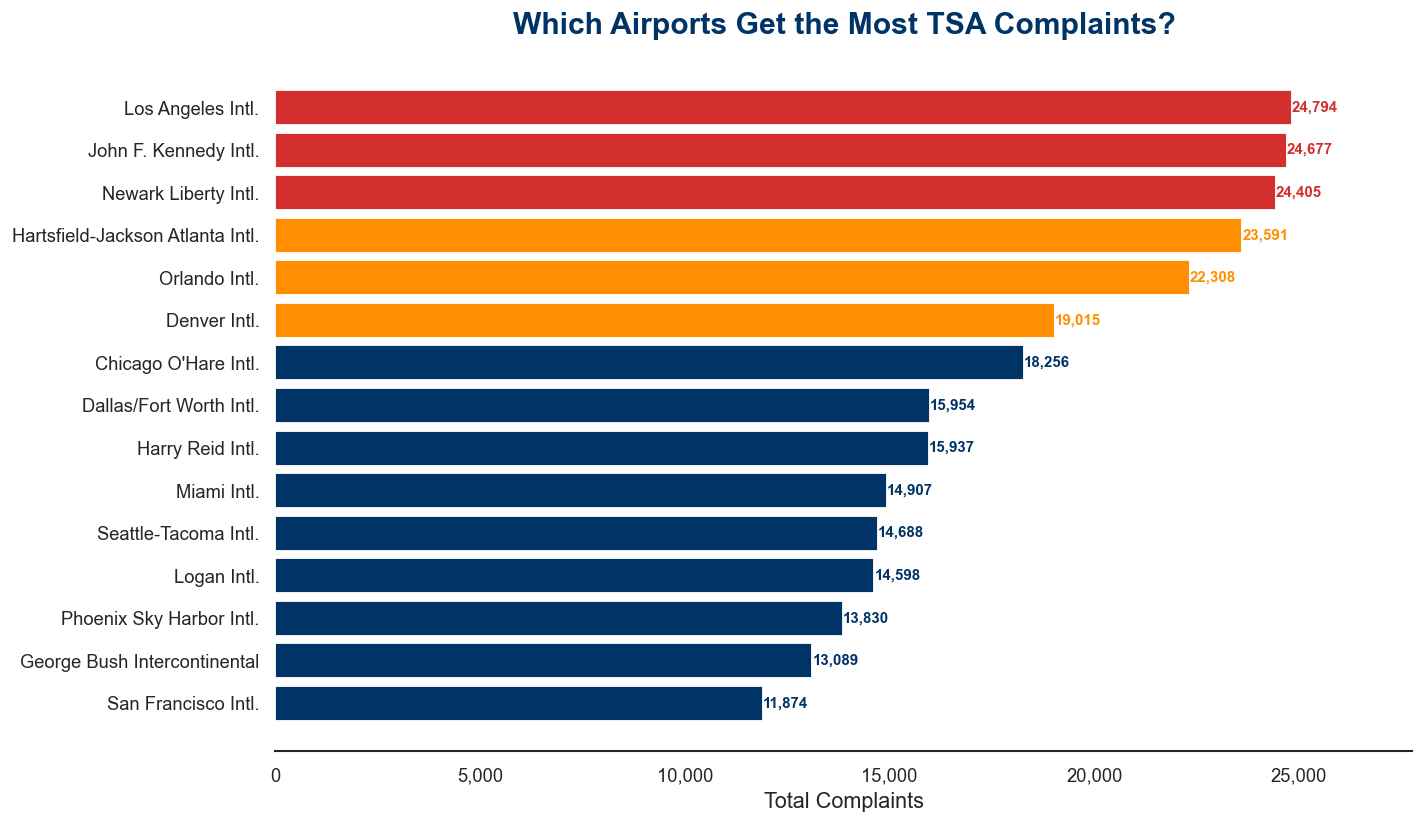

In [5]:
top15 = airport_geo.nlargest(15, 'total_complaints').sort_values('total_complaints')

fig, ax = plt.subplots(figsize=(12, 7))
colors = [ALERT_RED if i >= 12 else AMBER if i >= 9 else TSA_BLUE
          for i in range(len(top15))]
ax.barh(top15['short_name'], top15['total_complaints'],
        color=colors, edgecolor='white', linewidth=0.5)

for i, (val, name) in enumerate(zip(top15['total_complaints'], top15['short_name'])):
    ax.text(val + 30, i, f'{val:,.0f}', va='center', fontsize=9,
            color=colors[i], fontweight='bold')

ax.set_xlabel('Total Complaints', fontsize=13)
ax.set_title('Which Airports Get the Most TSA Complaints?',
             fontsize=18, color=TSA_BLUE, pad=15)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_xlim(right=top15['total_complaints'].max() * 1.12)
sns.despine(left=True)
plt.tight_layout()
plt.show()

---
## 4 | Mapping Complaints — Where Are the Hot Spots? *(Spatial Visual)*

Plotting every airport on a U.S. map with bubble size proportional to complaints
reveals a clear coastal-hub pattern. The biggest hot spots cluster around the
nation's busiest travel corridors.

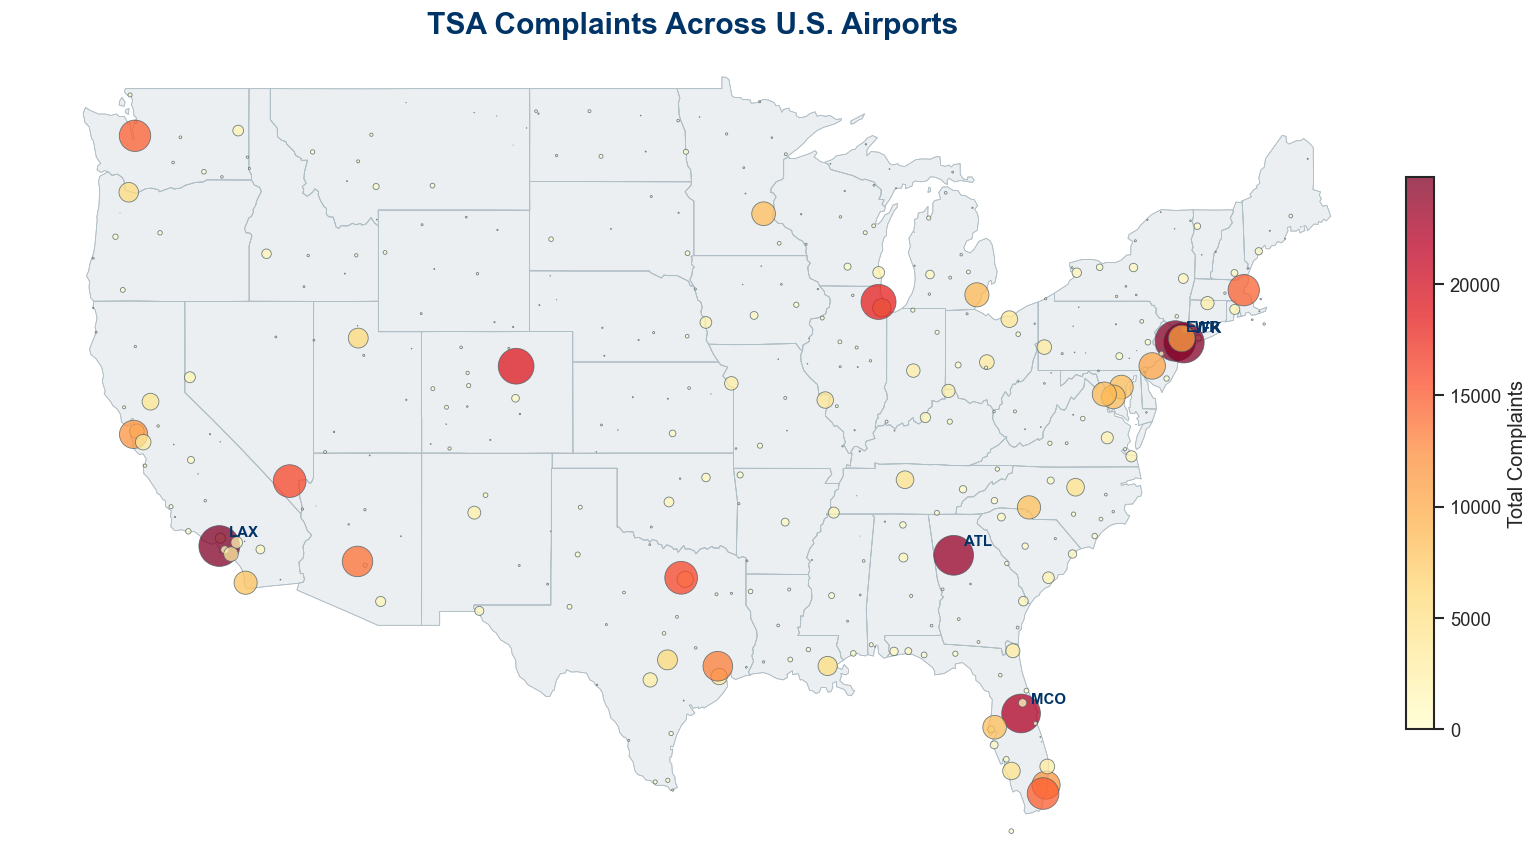

In [6]:
map_df = airport_geo[
    (airport_geo['longitude'].between(-130, -65)) &
    (airport_geo['latitude'].between(24, 50))
].copy()

us_states = gpd.read_file(
    'https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json'
)

fig, ax = plt.subplots(figsize=(14, 8))

us_states.boundary.plot(ax=ax, linewidth=0.5, color='#B0BEC5')
us_states.plot(ax=ax, color='#ECEFF1', edgecolor='#B0BEC5', linewidth=0.4)

scatter = ax.scatter(
    map_df['longitude'], map_df['latitude'],
    s=map_df['total_complaints'] / map_df['total_complaints'].max() * 600,
    c=map_df['total_complaints'], cmap='YlOrRd',
    alpha=0.75, edgecolors='#455A64', linewidth=0.5, zorder=5)
plt.colorbar(scatter, ax=ax, shrink=0.6, label='Total Complaints', pad=0.02)

top5 = map_df.nlargest(5, 'total_complaints')
for _, row in top5.iterrows():
    ax.annotate(row['code'], (row['longitude'], row['latitude']),
                fontsize=9, fontweight='bold', color=TSA_BLUE,
                textcoords='offset points', xytext=(6, 6), zorder=6)

ax.set_xlim(-128, -65)
ax.set_ylim(24, 50)
ax.set_title('TSA Complaints Across U.S. Airports',
             fontsize=18, color=TSA_BLUE, pad=15)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

---
## 5 | Seasonal Patterns — When Do Complaints Spike? *(Heat Map)*

Summer travel = more passengers = more friction. The heat map below shows monthly
complaint totals (summed across all years) for the 10 busiest airports. Look for
the bright-red bands in summer months.

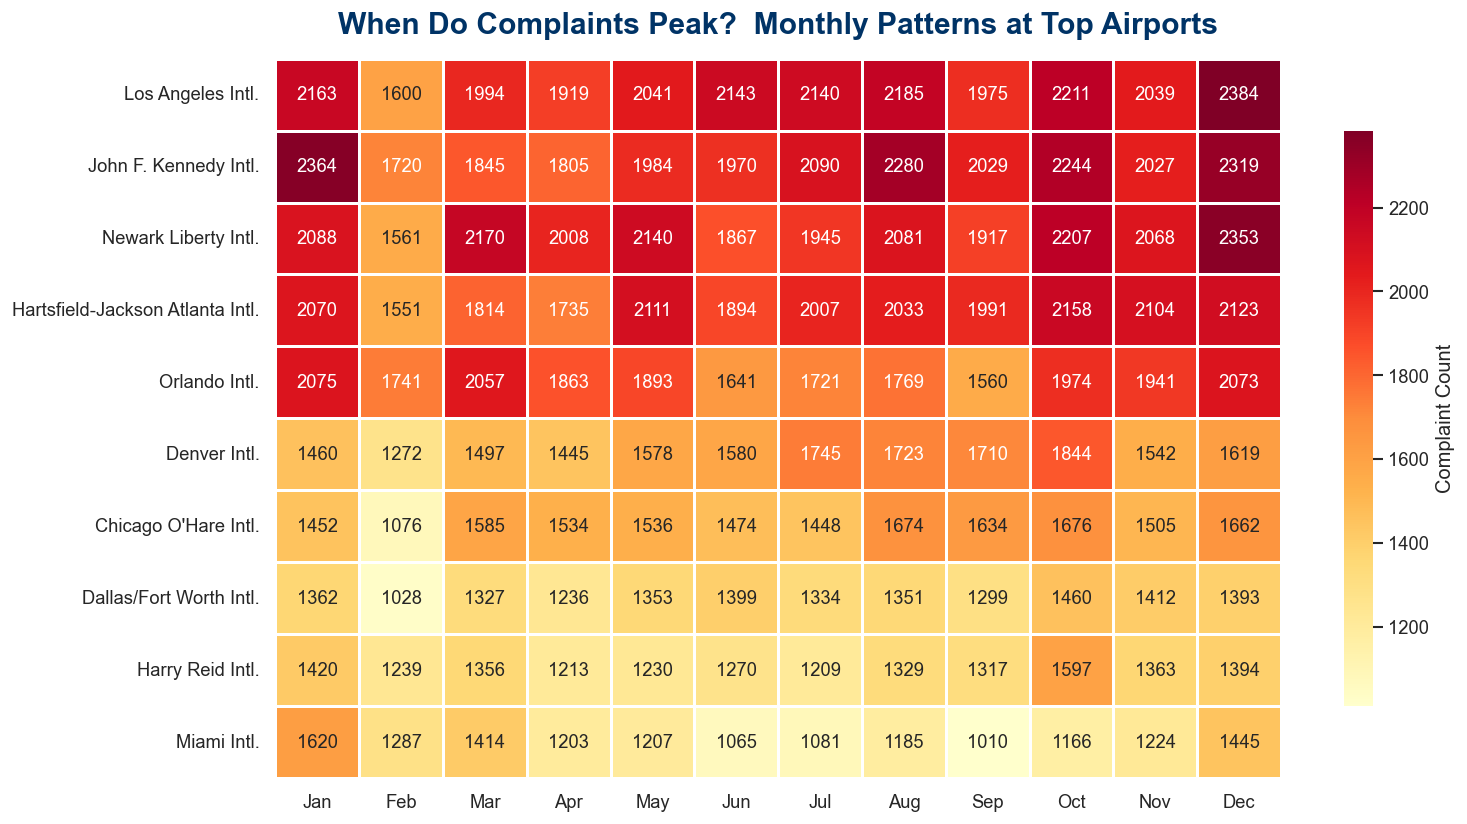

In [7]:
MONTH_LABELS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

top10_codes = airport_totals.nlargest(10, 'total_complaints')['code'].tolist()

heat_data = (airport_df[airport_df['airport'].isin(top10_codes)]
    .groupby(['airport', 'month'])['count'].sum()
    .reset_index()
    .pivot(index='airport', columns='month', values='count'))
heat_data.columns = MONTH_LABELS

name_map = airport_geo.set_index('code')['short_name'].to_dict()
heat_data.index = heat_data.index.map(lambda x: name_map.get(x, x))

heat_data['_total'] = heat_data.sum(axis=1)
heat_data = heat_data.sort_values('_total', ascending=False).drop(columns='_total')

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(heat_data, annot=True, fmt='.0f', cmap='YlOrRd',
            linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'Complaint Count', 'shrink': 0.8}, ax=ax)
ax.set_title('When Do Complaints Peak?  Monthly Patterns at Top Airports',
             fontsize=18, color=TSA_BLUE, pad=15)
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

---
## 6 | Complaint Categories — What Goes Wrong? *(Box Plot)*

Some categories — like screening and property handling — dominate the complaint
landscape. The box plot reveals not just medians but the *spread* and outlier
months that signal systemic issues.

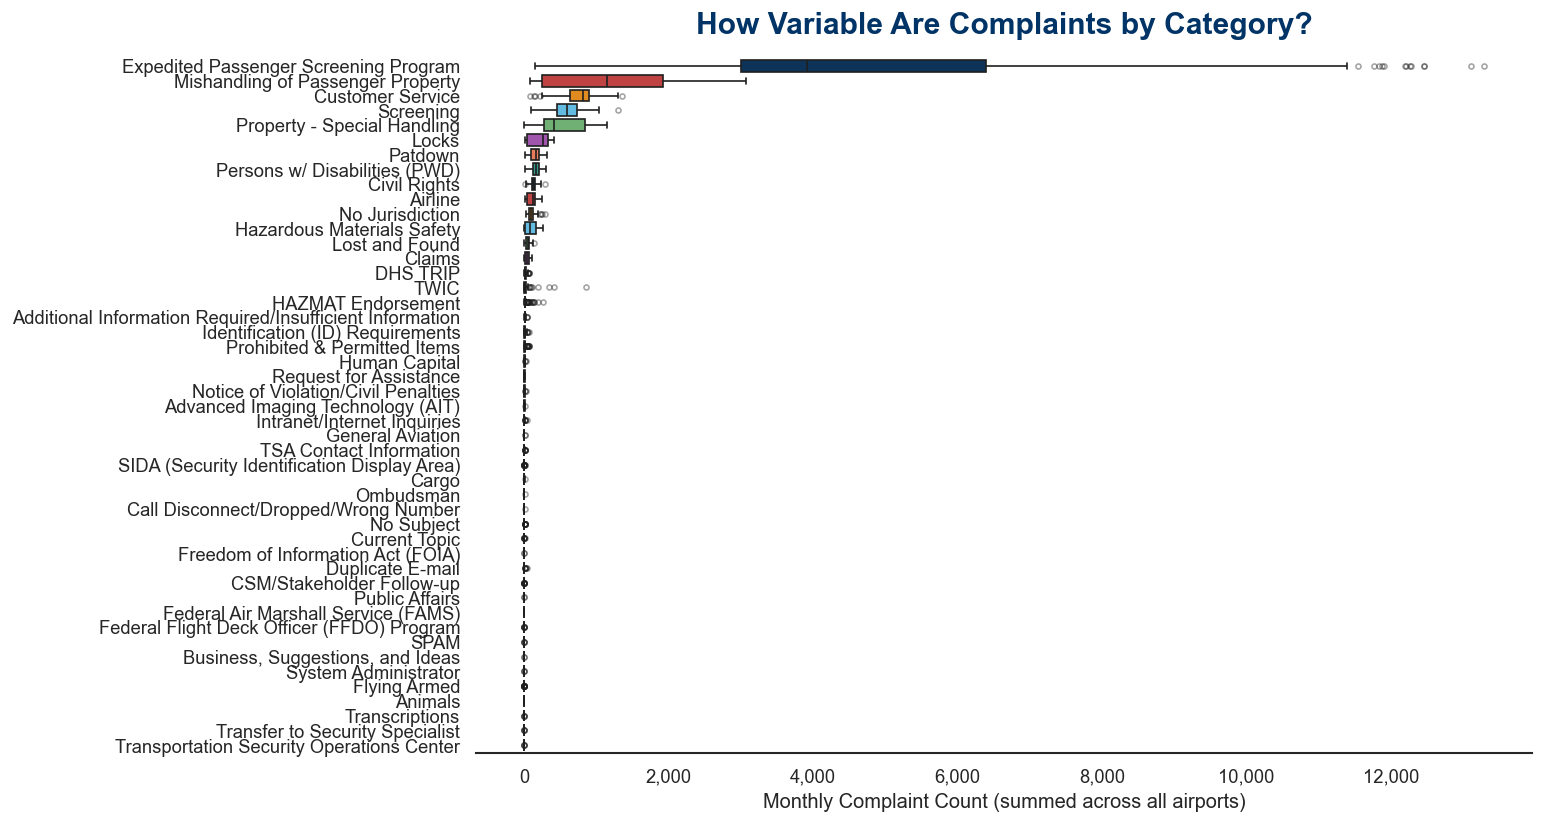

In [8]:
cat_monthly = (category_df
    .groupby(['clean_cat', 'year_month'])['count'].sum()
    .reset_index())

order = (cat_monthly.groupby('clean_cat')['count']
    .median().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(13, 7))
sns.boxplot(
    data=cat_monthly, x='count', y='clean_cat', order=order,
    palette=PALETTE,
    flierprops=dict(marker='o', markersize=3, alpha=0.4),
    ax=ax)
ax.set_title('How Variable Are Complaints by Category?',
             fontsize=18, color=TSA_BLUE, pad=15)
ax.set_xlabel('Monthly Complaint Count (summed across all airports)', fontsize=12)
ax.set_ylabel('')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(left=True)
plt.tight_layout()
plt.show()

---
## 7 | Trend Check — Are Things Getting Better or Worse?

Tracking the top complaint categories over time reveals whether TSA is improving
or whether certain problem areas are stubbornly persistent.

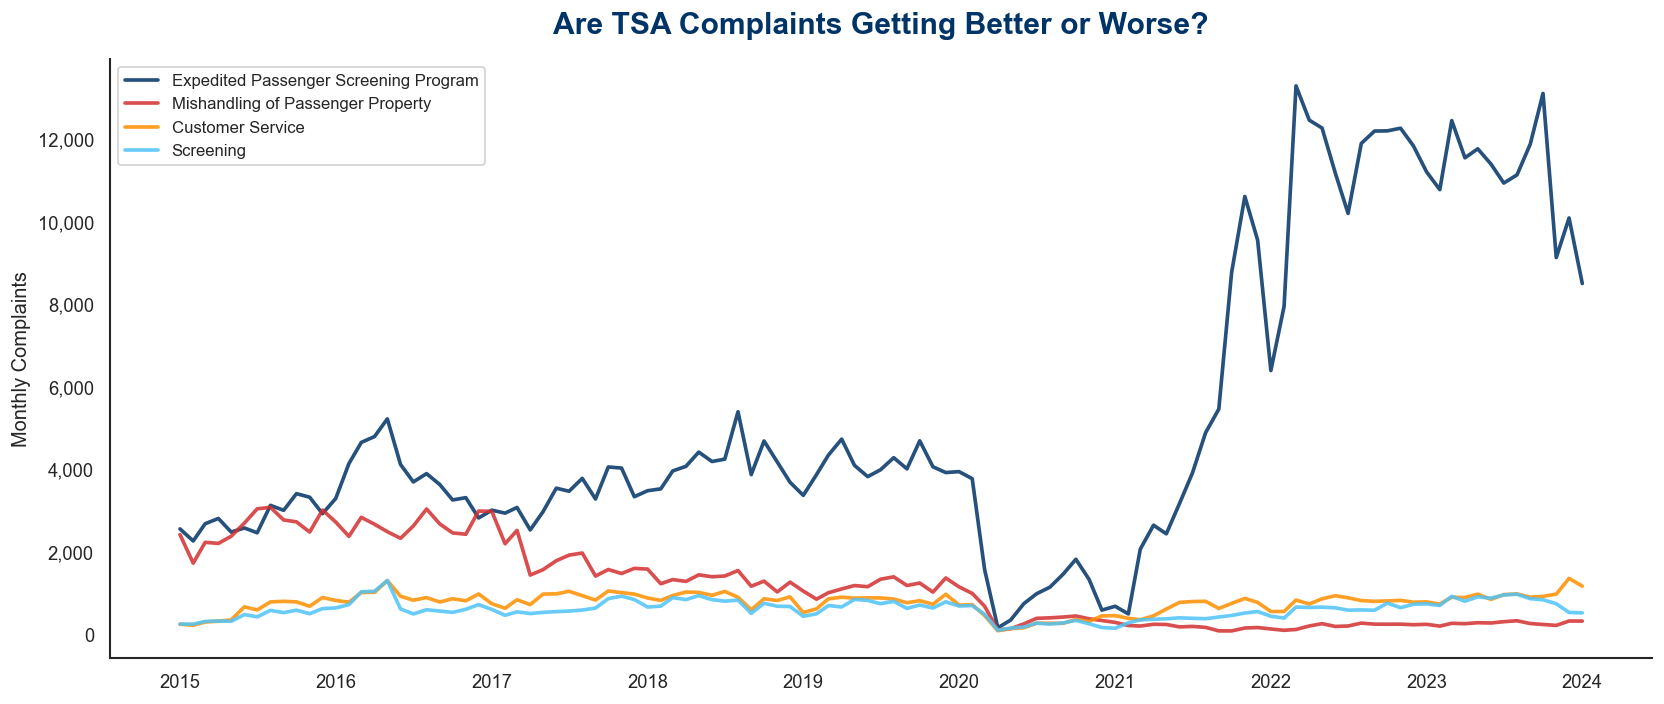

In [9]:
cat_trends = (category_df
    .groupby(['date', 'clean_cat'])['count'].sum()
    .reset_index())

top_cats = cat_trends.groupby('clean_cat')['count'].sum().nlargest(4).index.tolist()
trend_data = cat_trends[cat_trends['clean_cat'].isin(top_cats)].copy()

fig, ax = plt.subplots(figsize=(14, 6))
for i, cat in enumerate(top_cats):
    subset = trend_data[trend_data['clean_cat'] == cat].sort_values('date')
    ax.plot(subset['date'], subset['count'], label=cat,
            color=PALETTE[i], linewidth=2.2, alpha=0.85)

ax.set_title('Are TSA Complaints Getting Better or Worse?',
             fontsize=18, color=TSA_BLUE, pad=15)
ax.set_ylabel('Monthly Complaints', fontsize=12)
ax.set_xlabel('')
ax.legend(loc='upper left', frameon=True, fontsize=10, framealpha=0.9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.show()

---
## 8 | The Details — What Exactly Are Travelers Complaining About?

Drilling into the top subcategories shows the *specific* pain points travelers
experience. This lollipop chart ranks the 15 most-reported issues.

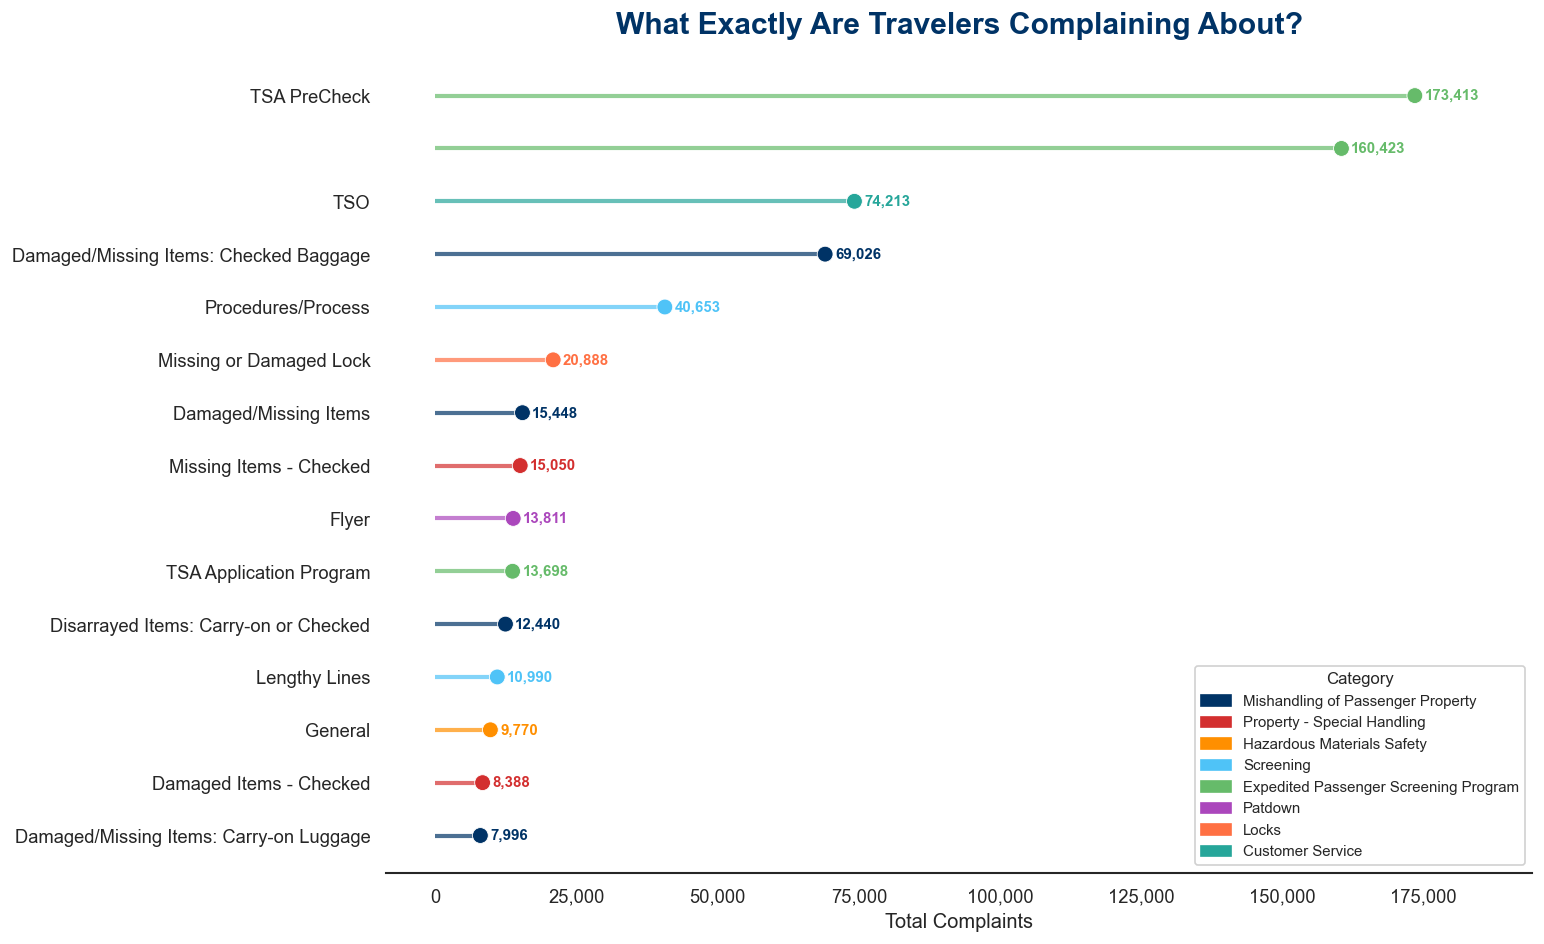

In [10]:
subcat_totals = (subcat_df
    .groupby(['clean_cat', 'clean_subcat'])['count'].sum()
    .reset_index()
    .sort_values('count', ascending=False)
    .head(15)
    .sort_values('count'))

subcat_totals['label'] = (subcat_totals['clean_subcat']
    .str.lstrip('*')
    .str.replace('--', ': ', regex=False)
    .str[:50])

unique_cats = subcat_totals['clean_cat'].unique()
cat_color_map = {cat: PALETTE[i % len(PALETTE)] for i, cat in enumerate(unique_cats)}
colors = [cat_color_map[c] for c in subcat_totals['clean_cat']]

fig, ax = plt.subplots(figsize=(13, 8))
y_pos = range(len(subcat_totals))
ax.hlines(y=y_pos, xmin=0, xmax=subcat_totals['count'],
          color=colors, linewidth=2.5, alpha=0.7)
ax.scatter(subcat_totals['count'], y_pos, color=colors, s=90, zorder=5,
           edgecolors='white', linewidth=0.5)

for i, val in enumerate(subcat_totals['count']):
    ax.text(val + subcat_totals['count'].max() * 0.01, i,
            f'{val:,.0f}', va='center', fontsize=9, color=colors[i], fontweight='bold')

ax.set_yticks(list(y_pos))
ax.set_yticklabels(subcat_totals['label'])
ax.set_title('What Exactly Are Travelers Complaining About?',
             fontsize=18, color=TSA_BLUE, pad=15)
ax.set_xlabel('Total Complaints', fontsize=12)
ax.set_xlim(right=subcat_totals['count'].max() * 1.12)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

handles = [mpatches.Patch(color=cat_color_map[c], label=c) for c in unique_cats]
ax.legend(handles=handles, title='Category', loc='lower right',
          fontsize=9, title_fontsize=10, framealpha=0.9)
sns.despine(left=True)
plt.tight_layout()
plt.show()

---
## 9 | Know Before You Go — Traveler Recommendations

Based on the data, here's what you can do to make your next trip smoother:

**1. Allow extra time at LAX, JFK, ORD, and SFO.** These airports consistently lead in complaint volume across nearly every category.

**2. Secure your checked bags.** "Damaged / Missing Items -- Checked Baggage" is the single largest subcategory of complaints. Use TSA-approved locks and keep valuables in your carry-on.

**3. Travel outside of June--August if possible.** Summer months show clear complaint spikes at every major hub. Shoulder-season travel means fewer crowds and fewer incidents.

**4. Know the screening process.** "Screening / Pat-Down" complaints rank high. Review TSA's screening procedures before your trip so you know what is standard and what warrants a complaint.

**5. File a complaint when warranted.** If something goes wrong, file a formal complaint through the TSA Contact Center (tsa.gov/contact-center). Data like this analysis only exists because travelers speak up.

**Bottom line:** The data does not say "don't fly." It says *be prepared.* Knowing which airports and categories drive the most complaints helps you pack smarter, plan better, and advocate for yourself when things go sideways.

---
## 10 | Summary Paper — Audience, Purpose, Medium, Design & Ethical Considerations

**Audience**

This analysis is designed for the general traveling public — frequent flyers and
occasional travelers who want practical insight into TSA complaint patterns. The
audience is assumed to have no specialized knowledge of aviation security operations,
data analysis, or government reporting structures. All visuals prioritize immediate
comprehension over technical depth, jargon is avoided, and narrative titles guide
interpretation of each chart.

**Purpose**

The purpose is not merely informational — it carries a clear call to action. By
exposing which airports generate the most TSA complaints, what categories are most
common, and when complaints spike, this story empowers travelers to plan smarter.
The call to action: *know before you go.* Travelers connecting through high-complaint
airports during peak summer months should allow extra time, secure valuables, and
familiarize themselves with TSA's complaint process. The analysis also subtly
advocates for greater TSA accountability at outlier airports.

**Medium**

An infographic-style Jupyter notebook was selected as the medium. This format
combines code-driven reproducibility with a visually rich, narrative-driven layout
exportable to PDF. The infographic approach — bold colors, large titles, minimal
text — mirrors how travel blogs and consumer advocacy sites present information,
making it engaging for a non-technical audience.

**Design Choices — Gestalt Principles**

Gestalt principles guided every design decision. *Proximity* groups related charts
into thematic sections (where, when, what). *Similarity* is maintained through a
consistent TSA-blue color anchor across all visuals. *Figure-ground* contrast
ensures data elements pop against clean white backgrounds. *Closure* allows viewers
to perceive seasonal patterns in the heat map even where individual cells vary.

- **Color:** A functional hierarchy — TSA blue (#003366) for neutral data, alert red
  (#D32F2F) for high-complaint outliers, amber (#FF8F00) for moderate concern.
- **Text:** Large, bold titles double as narrative hooks. Each chart answers a
  traveler's question directly.
- **Alignment:** Consistently left-justified visuals with uniform margins.
- **Sizing:** Wide, landscape-oriented figures optimized for screen and print.
- **Spacing:** Generous whitespace between sections prevents cognitive overload.

**Ethical Considerations**

The data was sourced from publicly available TSA complaint records released through
government transparency mechanisms and hosted on GitHub. The IATA airport reference
data is an open, publicly maintained dataset. No personally identifiable information
exists in any dataset.

Key transformations include deduplication by report date (retaining only the most
recent publication for each time period) and filtering the IATA dataset to U.S.
airports only. Both are documented in the code. A critical limitation is clearly
disclosed: raw complaint counts do not normalize for passenger volume, so
high-traffic airports like LAX and JFK will naturally appear worse. The analysis
notes this caveat rather than making misleading per-capita claims without verified
passenger data.

No data was filtered without disclosure. Visualizations avoid truncated axes or
misleading scales. The primary risk — unfairly stigmatizing specific airports based
on volume alone — is mitigated by explicitly calling out the passenger-volume caveat
at multiple points.